<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/11-capstone/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 11: Capstone

This is the last module, and it puts everything together. In the capstone project (`04_capstone.ipynb`) you'll take the original, raw field records from the Palmer Station penguin study and build a complete system: cleaning and validating the data, choosing and evaluating a model honestly, saving it with everything it needs, and serving predictions through a web API with tests.

Until now you've written models by hand, which is the best way to understand them. Real projects use libraries for the standard parts, so this lesson introduces the last tools you need:

1. The shape of an ML system
2. scikit-learn: the library version of what you built
3. Pipelines: preprocessing that travels with the model
4. Leakage: how evaluation goes wrong
5. Cross-validation
6. Comparing models, starting from a baseline
7. Tuning hyperparameters without fooling yourself
8. Saving a model
9. Serving predictions with an API
10. After deployment

## Setup

scikit-learn, FastAPI (a web framework) and httpx (an HTTP client FastAPI uses for testing) are needed. Colab has scikit-learn; this cell installs the other two if they're missing.

In [1]:
import importlib.util

missing = [pkg for pkg in ["fastapi", "httpx"] if importlib.util.find_spec(pkg) is None]
if missing:
    packages = " ".join(missing)
    %pip install -q {packages}

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL)
print("scikit-learn", sklearn.__version__, "| penguins", penguins.shape)

scikit-learn 1.9.1 | penguins (344, 8)


In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. The shape of an ML system

A trained model is a small part of a working ML system. Here are the stages, and the question each one has to answer:

| stage | question | where it goes wrong |
|---|---|---|
| **Data collection** | What do we have, and how was it recorded? | IDs that aren't IDs, units that change, labels that are guesses |
| **Validation and cleaning** | Is it what we think it is? | silent type conversions, dropped rows nobody counted |
| **Features** | What will we know **at prediction time**? | using information the real system won't have |
| **Splitting** | What does "new data" mean for this problem? | test data leaking into training, splits that don't match real use |
| **Training and selection** | Which model, which settings? | tuning on the test set, chasing noise |
| **Evaluation** | How good is it, really, and for whom? | one number without an interval; no baseline |
| **Packaging** | Can it run somewhere else? | weights saved without preprocessing, version mismatches |
| **Serving** | How do people and programs use it? | no input validation, no way to say "I don't know" |
| **Monitoring** | Is it still working? | the world changes and nobody notices |

You've met most of these problems already in this course. The capstone deals with all of them on one dataset.

## 2. scikit-learn: the library version of what you built

**scikit-learn** is the standard library for classical machine learning in Python. Almost everything in it follows one interface, the one you've been writing yourself since Module 3:

- **`fit(X, y)`** learns from data and returns the object itself.
- **`predict(X)`** (and `predict_proba(X)` for classifiers) makes predictions.
- **`transform(X)`** changes data, for preprocessing steps like scaling.
- Learned values end in an underscore: `coef_`, `mean_`, `classes_`.

Before trusting a library, check it against something you understand. In Module 9 you trained logistic regression with Newton's method to predict penguin sex. scikit-learn's version should find the same weights:

In [4]:
from sklearn.linear_model import LogisticRegression

MEASUREMENTS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
data = penguins.dropna(subset=MEASUREMENTS + ["sex"])
X_raw = data[MEASUREMENTS].to_numpy()
X = np.column_stack([(X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0),
                     data["species"].eq("Chinstrap"), data["species"].eq("Gentoo")]).astype(float)
y = data["sex"].eq("male").to_numpy(dtype=float)


def newton_logistic(X, y, iterations=15):                 # Module 9, in brief
    A = np.column_stack([X, np.ones(len(X))])
    theta = np.zeros(A.shape[1])
    for _ in range(iterations):
        p = 1 / (1 + np.exp(-A @ theta))
        hessian = A.T @ (A * (p * (1 - p))[:, None]) / len(y)
        theta -= np.linalg.solve(hessian, A.T @ (p - y) / len(y))
    return theta


ours = newton_logistic(X, y)
library = LogisticRegression(C=np.inf, tol=1e-10, max_iter=1000).fit(X, y)   # C = inf: no penalty
theirs = np.append(library.coef_[0], library.intercept_[0])

print("ours:   ", ours.round(3))
print("sklearn:", theirs.round(3))
print("largest difference:", f"{np.abs(ours - theirs).max():.1e}")

ours:    [ 3.352  3.191  0.291  4.716 -6.98  -8.354  4.684]
sklearn: [ 3.352  3.191  0.291  4.716 -6.98  -8.354  4.684]
largest difference: 2.6e-06


The same model. (`tol=1e-10` asks scikit-learn's optimiser to keep going until the weights stop changing; with its default tolerance they'd agree to about two decimal places.) Two things to notice:

- **`C` is the inverse of the regularisation strength**: smaller `C` means a stronger L2 penalty (Module 10's `l2` is roughly `1 / (C · n)`). scikit-learn's default is `C=1.0`, so its logistic regression is **regularised by default**. `C=np.inf` turns the penalty off to match our version. Defaults like this are worth knowing; they quietly change results.
- The library didn't need a learning rate or an iteration count from us. It's also tested by thousands of users. That's the trade: for standard methods, use the library, and keep your understanding for checking it and for the parts that aren't standard.

## 3. Pipelines: preprocessing that travels with the model

Real tables mix numeric and text columns, and have missing values. Each kind needs its own preparation:

- **numeric columns**: fill missing values, then standardise
- **categorical columns**: turn categories into 0/1 columns (**one-hot encoding**)

A **`ColumnTransformer`** applies different steps to different columns. A **`Pipeline`** chains steps so the whole thing behaves like a single model with `fit` and `predict`:

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), MEASUREMENTS),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), ["species", "island"]),
])
model = make_pipeline(preprocess, LogisticRegression(max_iter=1000))

labelled = penguins.dropna(subset=["sex"])
model.fit(labelled, labelled["sex"])
print("features the model sees:")
print(model[:-1].get_feature_names_out())
print("\ntraining accuracy:", round(model.score(labelled, labelled["sex"]), 3))

features the model sees:
['numeric__bill_length_mm' 'numeric__bill_depth_mm'
 'numeric__flipper_length_mm' 'numeric__body_mass_g'
 'categorical__species_Adelie' 'categorical__species_Chinstrap'
 'categorical__species_Gentoo' 'categorical__island_Biscoe'
 'categorical__island_Dream' 'categorical__island_Torgersen']

training accuracy: 0.928


Why this matters:

- **The pipeline takes the raw DataFrame.** `model.predict(new_penguins)` does the imputing, scaling and encoding with the statistics learned during `fit`. Module 10's "saved the weights but not the scaler" bug can't happen, because they're one object.
- **`handle_unknown="ignore"`** means a category never seen in training (a new island, say) becomes all zeros instead of crashing the prediction.
- **The labels can be strings.** Classifiers handle `"male"` and `"female"` themselves; `model.classes_` says which order the probability columns are in.

Missing values are handled inside the pipeline too:

In [6]:
new = pd.DataFrame([{"species": "Gentoo", "island": "Biscoe", "bill_length_mm": 49.1, "bill_depth_mm": 15.7,
                     "flipper_length_mm": np.nan, "body_mass_g": 5600}])     # flipper not measured
print(model.classes_, model.predict_proba(new).round(3), model.predict(new))

['female' 'male'] [[0.035 0.965]] ['male']


The missing flipper length was filled with the training median before scaling. Whether that's acceptable is a judgement call: it's fine for an occasional gap, but a model that mostly sees imputed values is a different model. The capstone API will warn when it has to do this.

## 4. Leakage: how evaluation goes wrong

**Leakage** is when information from the test data influences training. The model then looks better in evaluation than it will be in real use. It's the most common serious mistake in applied ML, and it almost never causes an error message.

A dramatic example. Make a dataset of **pure noise**: 100 samples, 5,000 random features, and random labels. No model can genuinely do better than 50%. Now do something that looks reasonable: pick the 20 features most correlated with the labels, then cross-validate a model on those 20.

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score

rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, size=100)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# wrong: features chosen using ALL the data, then cross-validated
chosen = SelectKBest(f_classif, k=20).fit(X_noise, y_noise)
leaky = cross_val_score(LogisticRegression(), chosen.transform(X_noise), y_noise, cv=cv)

# right: selection is part of the pipeline, so it's redone inside each training fold
honest = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression()), X_noise, y_noise, cv=cv)

print(f"selection outside cross-validation: {leaky.mean():.0%} accuracy on pure noise")
print(f"selection inside the pipeline:      {honest.mean():.0%}")

selection outside cross-validation: 87% accuracy on pure noise
selection inside the pipeline:      50%


The leaky version reports high accuracy on data that contains **no signal at all**. With 5,000 features, some will correlate with the labels by chance, including in the rows later used for testing. Selecting them with all the data lets the test rows vote on which features to keep.

The same thing happens, more quietly, with any step that learns from data: scaling, imputing, encoding rare categories, choosing a threshold. The rule:

> **Anything that learns from data goes inside the pipeline**, so cross-validation refits it on each training fold, and the test fold stays unseen.

Other common forms of leakage:

- **Features from the future.** A "days until cancellation" column in a churn model; a lab result that's only available after the diagnosis it's meant to predict.
- **Duplicates across the split.** The same customer, patient or photo in both training and test. Use **group-aware** splits (`GroupKFold`) when rows belong to the same entity.
- **Time.** Training on next month to predict last month. When the model will be used on future data, test it on later data than it was trained on.

## 5. Cross-validation

A single train/test split gives one number, and Module 10's experiment showed how much that number depends on which rows land where. **k-fold cross-validation** uses every row for testing exactly once:

1. Split the data into k parts (**folds**), usually 5 or 10.
2. Train on k - 1 folds, test on the remaining one.
3. Repeat k times, so each fold is the test fold once, and report the mean and spread.

For classification, use **`StratifiedKFold`**, which keeps the class proportions the same in every fold. `shuffle=True` with a `random_state` makes the folds random but reproducible.

To try something new, the lesson uses a dataset that ships with scikit-learn: the **Wisconsin breast cancer data**, 569 tumour samples described by 30 measurements of cell nuclei from images, labelled malignant or benign.

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_validate

cancer = load_breast_cancer(as_frame=True)
X_c, y_c = cancer.data, cancer.target                     # target: 1 = benign, 0 = malignant
print(X_c.shape, "| benign:", int(y_c.sum()), "malignant:", int((y_c == 0).sum()))

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
scores = cross_validate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_c, y_c,
                        cv=cv10, scoring=["accuracy", "recall"])
print("accuracy per fold:", scores["test_accuracy"].round(3))
print(f"accuracy {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")

(569, 30) | benign: 357 malignant: 212


accuracy per fold: [0.947 0.947 0.965 1.    1.    0.965 0.982 1.    0.982 0.982]
accuracy 0.977 ± 0.019


The fold scores vary by several points; the mean is the estimate, and the spread says how much a single split could mislead. `cross_validate` can compute several metrics at once, and returns timings too.

## 6. Comparing models, starting from a baseline

Always include a **baseline**: the simplest possible "model". `DummyClassifier` predicts the most common class. If a model can't beat it clearly, it hasn't learned anything useful.

scikit-learn's consistent interface makes comparing very different models a loop. Two you haven't met before:

- **Random forest**: many decision trees, each trained on a random resample of the data and a random subset of features, voting together.
- **Histogram gradient boosting**: trees built one after another, each correcting the errors of the ones before. Often the strongest choice for tables.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

candidates = {
    "baseline (most common class)": DummyClassifier(),
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "k-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=10)),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=0),
    "gradient boosting": HistGradientBoostingClassifier(random_state=0),
}
fold_scores = {name: cross_val_score(m, X_c, y_c, cv=cv10) for name, m in candidates.items()}
comparison = pd.DataFrame({name: [s.mean(), s.std()] for name, s in fold_scores.items()},
                          index=["mean", "std"]).T.sort_values("mean", ascending=False)
comparison.round(3)

,mean,std
logistic regression,0.977,0.019
gradient boosting,0.968,0.022
k-nearest neighbours,0.967,0.029
random forest,0.963,0.024
baseline (most common class),0.627,0.007


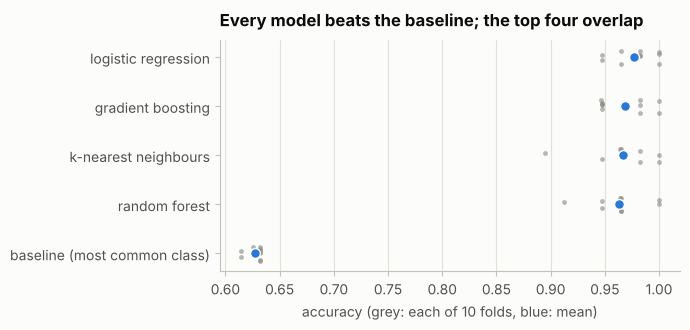

In [10]:
order = comparison.index[::-1]
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=10)     # spread the dots so overlaps show
fig, ax = plt.subplots(figsize=(7, 3.4))
for row, name in enumerate(order):
    s = fold_scores[name]
    ax.scatter(s, row + jitter, color=MUTED, s=12, alpha=0.6, zorder=2)
    ax.scatter([s.mean()], [row], color=PALETTE[0], s=50, zorder=3, edgecolors=SURFACE, linewidths=1)
ax.set_yticks(range(len(order)), order)
ax.grid(axis="y", visible=False)
ax.set_xlabel("accuracy (grey: each of 10 folds, blue: mean)")
ax.set_title("Every model beats the baseline; the top four overlap")
fig.tight_layout()
plt.show()

Every real model beats the 63% baseline by a wide margin, and the top four are within a couple of points of each other, with fold-to-fold spreads larger than the gaps between them. With differences this small, the ranking could easily change with a different random split.

When models are this close, prefer the **simplest** one that's within about one standard deviation of the best. A logistic regression is faster, easier to explain, easier to check and less likely to break in surprising ways. Here it's also at the top.

Accuracy isn't the only consideration either. In this data, missing a malignant tumour is far worse than a false alarm, so recall on the malignant class, and where to set the decision threshold, would matter more than overall accuracy. Choosing the metric is part of the problem, not a detail.

## 7. Tuning hyperparameters without fooling yourself

**Hyperparameters** are settings chosen before training: `C` for logistic regression, `k` for nearest neighbours, the number of trees. **`GridSearchCV`** tries every combination with cross-validation and keeps the best:

In [11]:
from sklearn.model_selection import GridSearchCV

pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
search = GridSearchCV(pipeline, {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=cv10)
search.fit(X_c, y_c)

results = pd.DataFrame(search.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
print(results.round(3).to_string(index=False))
print("\nbest:", search.best_params_, f"score {search.best_score_:.3f}")

 param_logisticregression__C  mean_test_score  std_test_score
                       0.001            0.903           0.036
                       0.010            0.951           0.027
                       0.100            0.974           0.018
                       1.000            0.977           0.019
                      10.000            0.972           0.014
                     100.000            0.972           0.018

best: {'logisticregression__C': 1} score 0.977


The parameter names follow a pattern: the step's name in the pipeline (`make_pipeline` names steps after their class, in lowercase), two underscores, then the parameter.

There's a catch. `best_score_` is the best of six cross-validated scores, and picking the maximum of several noisy numbers **overestimates**: some of the winner's lead is luck. It's the same effect as leakage, on a smaller scale. The tuning used every fold for choosing, so no fold is left to measure the choice honestly.

**Nested cross-validation** fixes it: an outer loop holds out each fold in turn, and the whole grid search runs **inside** the remaining data. Because `GridSearchCV` is itself an estimator, that's one line:

In [12]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
nested = cross_val_score(search, X_c, y_c, cv=outer)
print(f"best score inside the search: {search.best_score_:.3f}")
print(f"nested estimate:              {nested.mean():.3f} ± {nested.std():.3f}")

best score inside the search: 0.977
nested estimate:              0.975 ± 0.012


The nested estimate is the honest number to report for "logistic regression, with `C` tuned by grid search". Here the gap is small, because there's only one hyperparameter and plenty of signal. With many hyperparameters and little data, it can be large. In the capstone you'll see it clearly.

In practice: use `GridSearchCV` (or `RandomizedSearchCV` for bigger grids) to **choose** settings, and nested cross-validation or a separate untouched test set to **report** performance.

## 8. Saving a model

A fitted pipeline is a Python object. **joblib** (installed with scikit-learn) saves it to a file and loads it back:

In [13]:
import joblib

out = Path("work/lesson11")
out.mkdir(parents=True, exist_ok=True)

final = search.best_estimator_                   # already refitted on all the data by GridSearchCV
joblib.dump(final, out / "cancer_model.joblib")
loaded = joblib.load(out / "cancer_model.joblib")
print("same predictions:", np.array_equal(loaded.predict(X_c), final.predict(X_c)))
print(f"file size: {(out / 'cancer_model.joblib').stat().st_size:,} bytes")

same predictions: True
file size: 3,105 bytes


Three things to know about saved models:

- **Only load files you trust.** joblib uses Python's `pickle`, and loading a pickle can run any code its author chose. Never load a model file from an unknown source. (Formats like ONNX, or the `skops` library, exist partly for this reason.)
- **Versions matter.** A model saved with one version of scikit-learn may not load, or may behave differently, with another. Save the library versions next to the model, and pin them where the model is served.
- **Save what the model needs to be used correctly**, not just the model: the feature names and types it expects, the ranges it was trained on, its evaluation results, and the data it came from. The capstone saves a **bundle**: a dict with the pipeline and all of that metadata, in one file.

## 9. Serving predictions with an API

A model in a notebook helps one person. A model behind a **web API** can be used by a mobile app in the field, a spreadsheet macro, another team's service, anything that can send an HTTP request.

**FastAPI** is a popular Python framework for this. You describe the input with a **Pydantic** model, a class with typed fields, and FastAPI validates every request against it, rejecting bad input with a clear error before your code runs. Here's a small service for penguin **species**, trained on the clean data:

In [14]:
from typing import Literal

from fastapi import FastAPI
from pydantic import BaseModel, Field

clean = penguins.dropna(subset=MEASUREMENTS)
species_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
species_model.fit(clean[MEASUREMENTS], clean["species"])


class Penguin(BaseModel):
    bill_length_mm: float = Field(gt=0, lt=100)
    bill_depth_mm: float = Field(gt=0, lt=50)
    flipper_length_mm: float = Field(gt=0, lt=300)
    body_mass_g: float = Field(gt=0, lt=10_000)


app = FastAPI(title="Penguin species")


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(penguin: Penguin):
    row = pd.DataFrame([penguin.model_dump()])
    probabilities = species_model.predict_proba(row)[0]
    best = int(np.argmax(probabilities))
    return {"species": species_model.classes_[best], "probability": round(float(probabilities[best]), 3)}

- `@app.get("/health")` and `@app.post("/predict")` connect URL paths to functions. A health endpoint is standard: it lets other systems check the service is running.
- The `predict` function's argument is typed as `Penguin`, so FastAPI reads the request's JSON body, validates it, and passes a `Penguin` object. `Field(gt=0, lt=100)` adds range limits.
- Whatever the function returns is sent back as JSON.

To test an API you don't need to start a server. FastAPI's **`TestClient`** sends requests straight to the app:

In [15]:
from fastapi.testclient import TestClient

client = TestClient(app)
print(client.get("/health").json())

response = client.post("/predict", json={"bill_length_mm": 46.5, "bill_depth_mm": 14.8,
                                         "flipper_length_mm": 217, "body_mass_g": 5200})
print(response.status_code, response.json())

{'status': 'ok'}
200 {'species': 'Gentoo', 'probability': 0.998}


And when the input is wrong:

In [16]:
bad = client.post("/predict", json={"bill_length_mm": -3, "bill_depth_mm": 14.8, "flipper_length_mm": 217})
print(bad.status_code)
for error in bad.json()["detail"]:
    print(f"  {error['loc'][-1]}: {error['msg']}")

422
  bill_length_mm: Input should be greater than 0
  body_mass_g: Field required


Status **422** means "the request was understood but its content is invalid", and the response lists every problem: a negative bill length and a missing body mass. The model code never ran. Validation at the boundary, as in Module 10, is built in.

To run the app as a real server, you'd save it in a file (say `app.py`) and start it with **uvicorn**: `uvicorn app:app --port 8000`. FastAPI then also serves interactive documentation at `http://localhost:8000/docs`, generated from the Pydantic models. The capstone does exactly this.

## 10. After deployment

A deployed model meets data it has never seen, and the world it was trained on keeps changing. Three habits catch problems early:

- **Log every prediction**: the input, the output, the model version and the time. Without this you can't investigate a complaint or measure performance later, when the true answers arrive.
- **Watch the inputs.** If incoming data drifts away from the training data (new equipment, a new site, a change in units), predictions become unreliable before anyone notices the accuracy dropping. A simple start: compare each input with the range seen in training, and warn when it falls outside. You'll write a drift report in the exercises.
- **Know when to say "I don't know".** A classifier always outputs a class, even for inputs it has no business judging. Returning "unsure" when the probability is close to 0.5, or when inputs look unusual, is often more useful than a confident guess.

Finally, document the model with a **model card**: a short description of what it does, what data it was trained on, how it was evaluated, how well it works and for whom, and where it shouldn't be used. The capstone ends with one.

## Summary

- An ML system is data, validation, features, splitting, training, evaluation, packaging, serving and monitoring. Each stage has its own failure modes.
- **scikit-learn** follows `fit` / `predict` / `transform`. Check it against what you understand; know its defaults (`LogisticRegression` is regularised with `C=1`).
- **Pipelines** with a `ColumnTransformer` bundle imputing, scaling and encoding with the model, so they're refitted inside cross-validation and saved together.
- **Leakage**: anything that learns from data goes inside the pipeline. Watch for future information, duplicates across splits, and time order. Feature selection outside cross-validation found 87% accuracy in pure noise.
- **Cross-validation** (`StratifiedKFold`, `cross_val_score`, `cross_validate`) uses every row for testing once; report the mean and spread.
- **Compare against a baseline**; when models are close, prefer the simplest. Choose the metric that matches the real cost of mistakes.
- **`GridSearchCV`** chooses hyperparameters; its best score is optimistic. **Nested CV** or an untouched test set gives the honest number.
- **joblib** saves pipelines. Only load trusted files; record versions; save a bundle with metadata.
- **FastAPI + Pydantic** turn a model into a validated web API; **`TestClient`** tests it without a server; **uvicorn** runs it.
- After deployment: log predictions, watch inputs for drift, allow "unsure", and write a model card.

Next, open `02_exercises.ipynb`.